Objetivo

Comparar los modelos entrenados en el notebook anterior para seleccionar el más adecuado para predecir la variable smoking.

La selección se realizará considerando principalmente el F1-Score de la clase positiva (smoking = 1), así como las diferencias de rendimiento entre los conjuntos de entrenamiento y prueba, con el objetivo de identificar posibles problemas de sobreajuste.

Una vez seleccionado el modelo, se documentará su rendimiento y se guardará para utilizarlo posteriormente en la predicción de nuevos registros.

In [1]:
import pandas as pd
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:

resultados = pd.DataFrame({
    "Modelo": [
        "Decision Tree inicial",
        "Decision Tree optimizado",
        "Random Forest inicial",
        "Random Forest controlado",
        "Random Forest optimizado",
        "XGBoost inicial",
        "XGBoost optimizado"
    ],
    "F1 Train": [0.66, 0.69, 1.00, 0.75, 1.00, 0.74, 0.80],
    "F1 Test": [0.65, 0.68, 0.72, 0.70, 0.73, 0.70, 0.70]
})

resultados["Diferencia"] = (
    resultados["F1 Train"] - resultados["F1 Test"]
).round(2)

resultados.sort_values(
    by="F1 Test",
    ascending=False
)

,Modelo,F1 Train,F1 Test,Diferencia
4,Random Forest optimizado,1.00,0.73,0.27
2,Random Forest inicial,1.00,0.72,0.28
3,Random Forest controlado,0.75,0.70,0.05
5,XGBoost inicial,0.74,0.70,0.04
6,XGBoost optimizado,0.80,0.70,0.10
1,Decision Tree optimizado,0.69,0.68,0.01
0,Decision Tree inicial,0.66,0.65,0.01


A partir de los resultados obtenidos, se decidió seleccionar el modelo Random Forest controlado.

Este modelo obtuvo un F1-Score de 0,75 en Train y 0,70 en Test para la clase fumador.

Aunque el Random Forest optimizado obtuvo un F1-Score mayor en Test (0,73), presentó un overfitting importante, ya que alcanzó 1,00 en Train.

En cambio el Random Forest controlado mostró resultados más parecidos entre Train y Test con una diferencia de 0,05.

Por este motivo se eligió el Random Forest controlado, buscando un modelo con menor overfitting y un rendimiento aceptable para predecir si una persona es fumadora.

#### Obtener los datos guardados previamente

In [3]:
X_train = joblib.load("../data/processed/X_train.joblib")
X_test = joblib.load("../data/processed/X_test.joblib")
y_train = joblib.load("../data/processed/y_train.joblib")
y_test = joblib.load("../data/processed/y_test.joblib")

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (35000, 26)
Test: (15000, 26)


In [4]:
# Se repdroduce la configuracion del Random forest controlado
modelo_final = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

modelo_final.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total 

In [5]:
train_pred = modelo_final.predict(X_train)
test_pred = modelo_final.predict(X_test)

print("Train")
print(classification_report(y_train, train_pred))

print("--------------------------------")

print("Test")
print(classification_report(y_test, test_pred))

Train
              precision    recall  f1-score   support

           0       0.88      0.81      0.84     22170
           1       0.71      0.80      0.75     12830

    accuracy                           0.81     35000
   macro avg       0.79      0.81      0.80     35000
weighted avg       0.82      0.81      0.81     35000

--------------------------------
Test
              precision    recall  f1-score   support

           0       0.84      0.78      0.81      9501
           1       0.66      0.74      0.70      5499

    accuracy                           0.76     15000
   macro avg       0.75      0.76      0.75     15000
weighted avg       0.77      0.76      0.77     15000



### Distribución de probabilidades predichas – Train vs Test

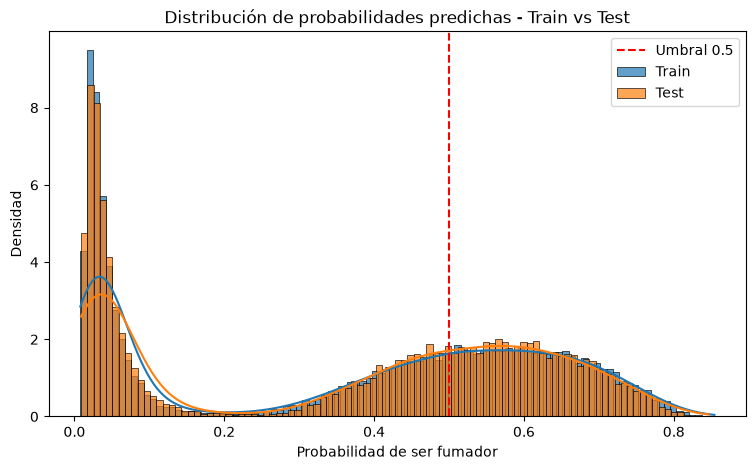

In [6]:
train_pred_proba = modelo_final.predict_proba(X_train)[:, 1]
test_pred_proba = modelo_final.predict_proba(X_test)[:, 1]


plt.figure(figsize=(9, 5))

sns.histplot(
    train_pred_proba,
    bins=100,
    kde=True,
    label="Train",
    stat="density",
    alpha=0.7
)

sns.histplot(
    test_pred_proba,
    bins=100,
    kde=True,
    label="Test",
    stat="density",
    alpha=0.7
)

plt.axvline(0.5, color="red", linestyle="--", label="Umbral 0.5")

plt.title("Distribución de probabilidades predichas - Train vs Test")
plt.xlabel("Probabilidad de ser fumador")
plt.ylabel("Densidad")
plt.legend()
plt.show()

Se compararon las probabilidades predichas por el Random Forest controlado para los conjuntos Train y Test.

Se observa que ambas distribuciones son muy similares lo que indica que el modelo presenta un comportamiento parecido en los dos conjuntos.

Hay una concentración importante de probabilidades cercanas a 0 y otra entre aproximadamente 0,35 y 0,75.

La línea roja representa el umbral de 0,5 utilizado para clasificar a las personas como fumadoras o no fumadoras.

Este resultado junto con la pequeña diferencia de F1-Score entre Train (0,75) y Test (0,70), sugiere que el modelo presenta un sobreajuste relativamente reducido.

#### Importancia relativa de atributos

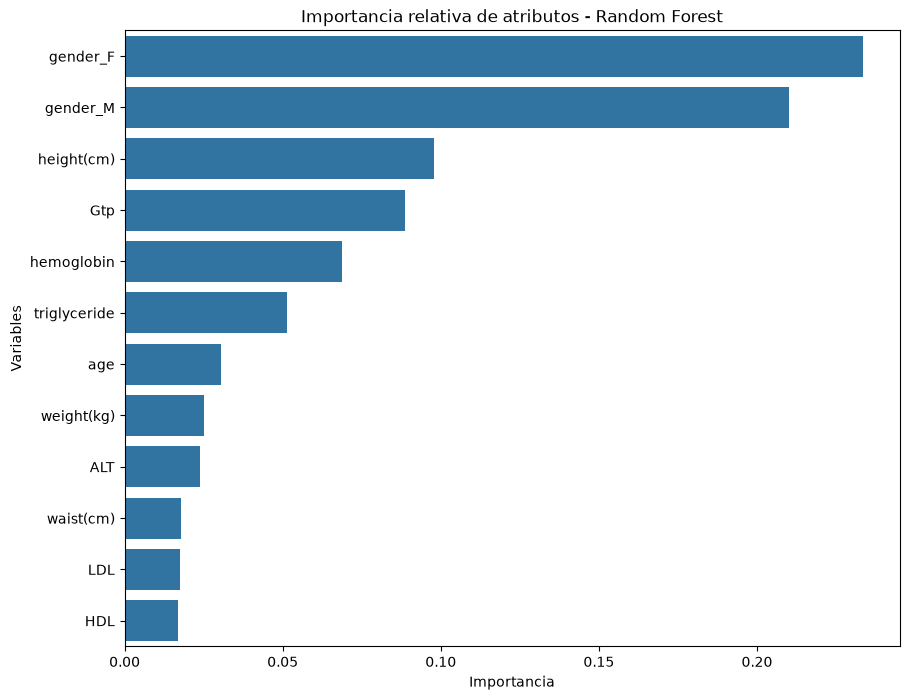

In [7]:
# Obtener la importancia de las variables
importancias = pd.Series(
    modelo_final.feature_importances_,
    index=X_train.columns
)

# Seleccionar las 12 más importantes
top_12 = importancias.sort_values(ascending=False).head(12)

# Graficar
plt.figure(figsize=(10, 8))

sns.barplot(
    x=top_12.values,
    y=top_12.index
)
plt.title("Importancia relativa de atributos - Random Forest")
plt.xlabel("Importancia")
plt.ylabel("Variables")
plt.show()

Se observa que el género es la característica más importante del modelo seguido por la altura, Gtp, hemoglobina y triglicéridos.

Estos resultados coinciden con algunos patrones encontrados durante el EDA, especialmente con las diferencias en el porcentaje de fumadores entre hombres y mujeres.

En conclusión, el modelo utiliza principalmente información relacionada con el género y algunas características físicas y de salud para realizar sus predicciones.

### Conclusion

Se entrenó nuevamente el Random Forest controlado utilizando los mismos datos y parámetros del notebook anterior obteniendo los mismos resultados.

El modelo alcanzó un F1-Score de 0,75 en entrenamiento y 0,70 en prueba para la clase positiva (smoking = 1), con un accuracy de 0,76 en Test.

El Recall de 0,74 indica que el modelo identifica aproximadamente el 74 % de los fumadores reales mientras que la Precision de 0,66 indica que el 66 % de las personas clasificadas como fumadoras efectivamente pertenece a esa clase.

Si bien este modelo no obtuvo el mayor F1-Score entre los algoritmos evaluados, se seleccionó por presentar un equilibrio razonable entre rendimiento predictivo y complejidad.

El modelo será utilizado para generar predicciones sobre los datos sin etiquetar proporcionados para el trabajo práctico.

### Guardado del modelo

In [8]:
import joblib
from pathlib import Path

Path("../models").mkdir(parents=True, exist_ok=True)

joblib.dump(
    modelo_final,
    "../models/random_forest_final.joblib"
)

print("Modelo guardado correctamente")

Modelo guardado correctamente


In [9]:
# Verificacion que se pueda cargar el modelo guardado y que funcione correctamente

modelo_cargado = joblib.load(
    "../models/random_forest_final.joblib"
)

predicciones = modelo_cargado.predict(X_test)

print(classification_report(y_test, predicciones))

              precision    recall  f1-score   support

           0       0.84      0.78      0.81      9501
           1       0.66      0.74      0.70      5499

    accuracy                           0.76     15000
   macro avg       0.75      0.76      0.75     15000
weighted avg       0.77      0.76      0.77     15000

